# Optional lab: Pet segmentation with U-Net
Dataset: [Oxford-IIIT Pet](https://www.kaggle.com/datasets/julinmaloof/the-oxfordiiit-pet-dataset).
This local run downloads the same original Oxford images and annotations through torchvision.
Trimap labels 1 (pet) and 3 (uncertain boundary) count as foreground; label 2 is background.
Train/validation/test are seeded 80/10/10 splits of all image IDs. Only validation selects the checkpoint.


**Submission: Priyanshi Goyal — A24ARIU0009**


In [2]:
import random, time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset,DataLoader
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF, InterpolationMode
import matplotlib.pyplot as plt
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ROOT=Path('data');EPOCHS=10;BATCH=16;SIZE=128
raw=OxfordIIITPet(ROOT,split='trainval',target_types='segmentation',download=True)
raw_test=OxfordIIITPet(ROOT,split='test',target_types='segmentation',download=True)
records=list(zip(raw._images,raw._segs))+list(zip(raw_test._images,raw_test._segs))
assert len({str(x) for x,y in records})==len(records)
indices=np.random.default_rng(SEED).permutation(len(records));a=int(.8*len(indices));b=int(.9*len(indices))
train_ids,val_ids,test_ids=indices[:a],indices[a:b],indices[b:]
print('train/validation/test:',len(train_ids),len(val_ids),len(test_ids))


train/validation/test: 5879 735 735


yorkshire_terrier_105.jpg image/mask size: (500, 333) trimap labels: [1 2 3]
havanese_144.jpg image/mask size: (500, 375) trimap labels: [1 2 3]
Maine_Coon_254.jpg image/mask size: (300, 225) trimap labels: [1 2 3]
Russian_Blue_244.jpg image/mask size: (300, 225) trimap labels: [1 2 3]
leonberger_84.jpg image/mask size: (500, 333) trimap labels: [1 2 3]


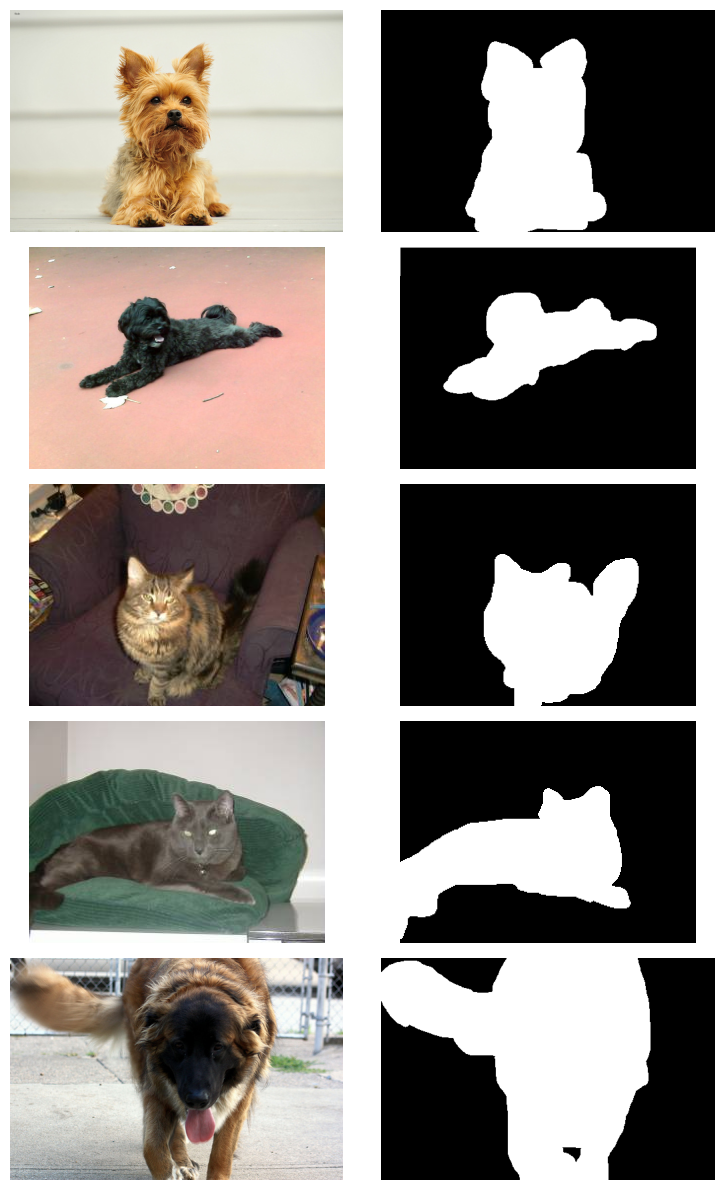

In [3]:
from PIL import Image
fig,axes=plt.subplots(5,2,figsize=(8,12))
for row,index in enumerate(train_ids[:5]):
    image=Image.open(records[index][0]).convert('RGB');mask=Image.open(records[index][1])
    assert image.size==mask.size
    print(Path(records[index][0]).name,'image/mask size:',image.size,'trimap labels:',np.unique(mask))
    axes[row,0].imshow(image);axes[row,1].imshow(np.asarray(mask)!=2,cmap='gray')
    for ax in axes[row]:ax.axis('off')
plt.tight_layout();plt.show()
class Pets(Dataset):
    def __init__(self,ids,augment=False):self.ids=ids;self.augment=augment
    def __len__(self):return len(self.ids)
    def __getitem__(self,i):
        p,m=records[self.ids[i]]
        image=Image.open(p).convert('RGB');mask=Image.open(m)
        image=TF.resize(image,[SIZE,SIZE],InterpolationMode.BILINEAR)
        mask=TF.resize(mask,[SIZE,SIZE],InterpolationMode.NEAREST)
        if self.augment:
            if random.random()<.5:image=TF.hflip(image);mask=TF.hflip(mask)
            angle=random.uniform(-10,10)
            image=TF.rotate(image,angle,InterpolationMode.BILINEAR)
            mask=TF.rotate(mask,angle,InterpolationMode.NEAREST,fill=2)
            image=TF.adjust_brightness(image,random.uniform(.9,1.1))
        return TF.to_tensor(image),torch.tensor((np.asarray(mask)!=2).copy(),dtype=torch.float32).unsqueeze(0)
train_loader=DataLoader(Pets(train_ids,True),batch_size=BATCH,shuffle=True,num_workers=2)
val_loader=DataLoader(Pets(val_ids),batch_size=BATCH,num_workers=2)
test_loader=DataLoader(Pets(test_ids),batch_size=BATCH,num_workers=2)


In [4]:
def block(cin,cout):
    return nn.Sequential(nn.Conv2d(cin,cout,3,padding=1),nn.ReLU(),nn.Conv2d(cout,cout,3,padding=1),nn.ReLU())
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1=block(3,32);self.enc2=block(32,64);self.enc3=block(64,128)
        self.pool=nn.MaxPool2d(2);self.bottom=block(128,256)
        self.up3=nn.ConvTranspose2d(256,128,2,2);self.dec3=block(256,128)
        self.up2=nn.ConvTranspose2d(128,64,2,2);self.dec2=block(128,64)
        self.up1=nn.ConvTranspose2d(64,32,2,2);self.dec1=block(64,32)
        self.out=nn.Conv2d(32,1,1)
    def forward(self,x,trace=False):
        e1=self.enc1(x);e2=self.enc2(self.pool(e1));e3=self.enc3(self.pool(e2));b=self.bottom(self.pool(e3))
        d3=self.dec3(torch.cat([self.up3(b),e3],1))
        d2=self.dec2(torch.cat([self.up2(d3),e2],1))
        d1=self.dec1(torch.cat([self.up1(d2),e1],1))
        y=self.out(d1)
        if trace:print({k:tuple(v.shape) for k,v in [('enc1',e1),('enc2',e2),('enc3',e3),('bottleneck',b),('dec3',d3),('dec2',d2),('dec1',d1),('logits',y)]})
        return y
model=UNet().to(DEVICE)
assert model(torch.rand(2,3,SIZE,SIZE,device=DEVICE),trace=True).shape==(2,1,SIZE,SIZE)


{'enc1': (2, 32, 128, 128), 'enc2': (2, 64, 64, 64), 'enc3': (2, 128, 32, 32), 'bottleneck': (2, 256, 16, 16), 'dec3': (2, 128, 32, 32), 'dec2': (2, 64, 64, 64), 'dec1': (2, 32, 128, 128), 'logits': (2, 1, 128, 128)}


Each 3×3 convolution combines neighbours. After stride-2 pooling, adjacent features are
separated by twice as many input pixels, so subsequent convolutions see a larger input area.
The bottleneck therefore has broad context but coarse location information. Concatenated skips
restore high-resolution local features for boundaries; upsampling alone cannot recover them.


One-epoch pipeline check: (0.4844941035825379, 0.739429349223326, 0.5865830279070406)


epoch 1 train/val BCE, val Dice/IoU: [0.5382920079418623, 0.4903517219485069, 0.7278442645448642, 0.5721345620349458] seconds 10.629668054985814


epoch 2 train/val BCE, val Dice/IoU: [0.4429102435284761, 0.4507404625821276, 0.7642365146727914, 0.6184326723899265] seconds 12.576167213963345


epoch 3 train/val BCE, val Dice/IoU: [0.37753556159548785, 0.41161781723807456, 0.7872436649061572, 0.6491358916259495] seconds 12.815016445005313


epoch 4 train/val BCE, val Dice/IoU: [0.3369916853277755, 0.3237528740548763, 0.8349286382352827, 0.7166330455248948] seconds 13.665457512019202


epoch 5 train/val BCE, val Dice/IoU: [0.31123123641503997, 0.30135758182629435, 0.8427635159881118, 0.7282552249531887] seconds 13.66314214200247


epoch 6 train/val BCE, val Dice/IoU: [0.2867493438090084, 0.29997969782676825, 0.8345619335347448, 0.7160929075072636] seconds 10.655989755061455


epoch 7 train/val BCE, val Dice/IoU: [0.2684407627213506, 0.26124406359633623, 0.8695624930909147, 0.7692265054691352] seconds 10.183944035088643


epoch 8 train/val BCE, val Dice/IoU: [0.25426488305703576, 0.2799136488616061, 0.8669779419168362, 0.7651907001559912] seconds 10.32534666697029


epoch 9 train/val BCE, val Dice/IoU: [0.24772567610834748, 0.24599242261072404, 0.8803631238718541, 0.7862934337392223] seconds 10.261842095060274


epoch 10 train/val BCE, val Dice/IoU: [0.23445504219946883, 0.2514324505718387, 0.8684566503780549, 0.7674974632374565] seconds 10.327966460958123


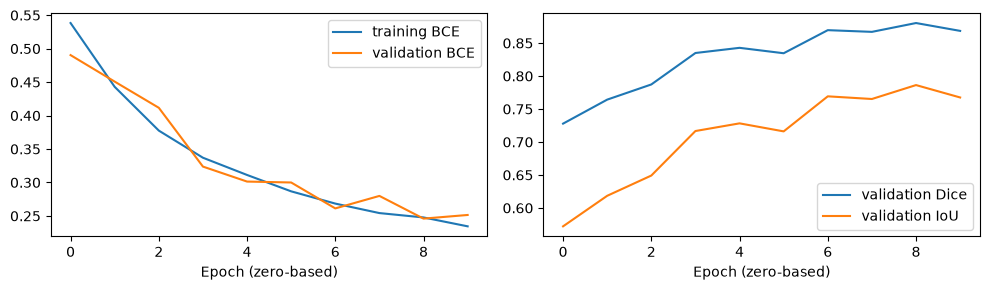

One held-out test evaluation: BCE, micro Dice, micro IoU (0.2431619427642044, 0.8794925936727476, 0.7849056496248515)


In [5]:
criterion=nn.BCEWithLogitsLoss()
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
@torch.no_grad()
def evaluate(loader):
    model.eval();intersection=predicted=truth=loss_sum=count=0
    for x,y in loader:
        x,y=x.to(DEVICE),y.to(DEVICE);logits=model(x)
        loss_sum+=criterion(logits,y).item()*len(x);count+=len(x)
        p=logits.sigmoid()>=.5;g=y.bool()
        intersection+=(p&g).sum().item();predicted+=p.sum().item();truth+=g.sum().item()
    return loss_sum/count,(2*intersection+1e-7)/(predicted+truth+1e-7),(intersection+1e-7)/(predicted+truth-intersection+1e-7)
# One-epoch pipeline run, then restart for the final ten-epoch experiment.
for x,y in train_loader:
    model.train();optimizer.zero_grad(set_to_none=True)
    loss=criterion(model(x.to(DEVICE)),y.to(DEVICE));loss.backward();optimizer.step()
print('One-epoch pipeline check:',evaluate(val_loader))
torch.manual_seed(SEED);random.seed(SEED)
model=UNet().to(DEVICE);optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
history=[];best=-1
for epoch in range(EPOCHS):
    started=time.perf_counter();model.train();total=0
    for x,y in train_loader:
        x,y=x.to(DEVICE),y.to(DEVICE);optimizer.zero_grad(set_to_none=True)
        loss=criterion(model(x),y);loss.backward();optimizer.step();total+=loss.item()*len(x)
    vl,dice,iou=evaluate(val_loader)
    history.append([total/len(train_ids),vl,dice,iou])
    if dice>best:
        best=dice;torch.save(model.state_dict(),'best_unet.pt')
    print('epoch',epoch+1,'train/val BCE, val Dice/IoU:',history[-1],'seconds',time.perf_counter()-started)
fig,axes=plt.subplots(1,2,figsize=(10,3))
h=np.array(history)
axes[0].plot(h[:,:2]);axes[0].legend(['training BCE','validation BCE'])
axes[1].plot(h[:,2:]);axes[1].legend(['validation Dice','validation IoU'])
for ax in axes:ax.set_xlabel('Epoch (zero-based)')
plt.tight_layout();plt.show()
model.load_state_dict(torch.load('best_unet.pt',map_location=DEVICE,weights_only=True))
print('One held-out test evaluation: BCE, micro Dice, micro IoU',evaluate(test_loader))


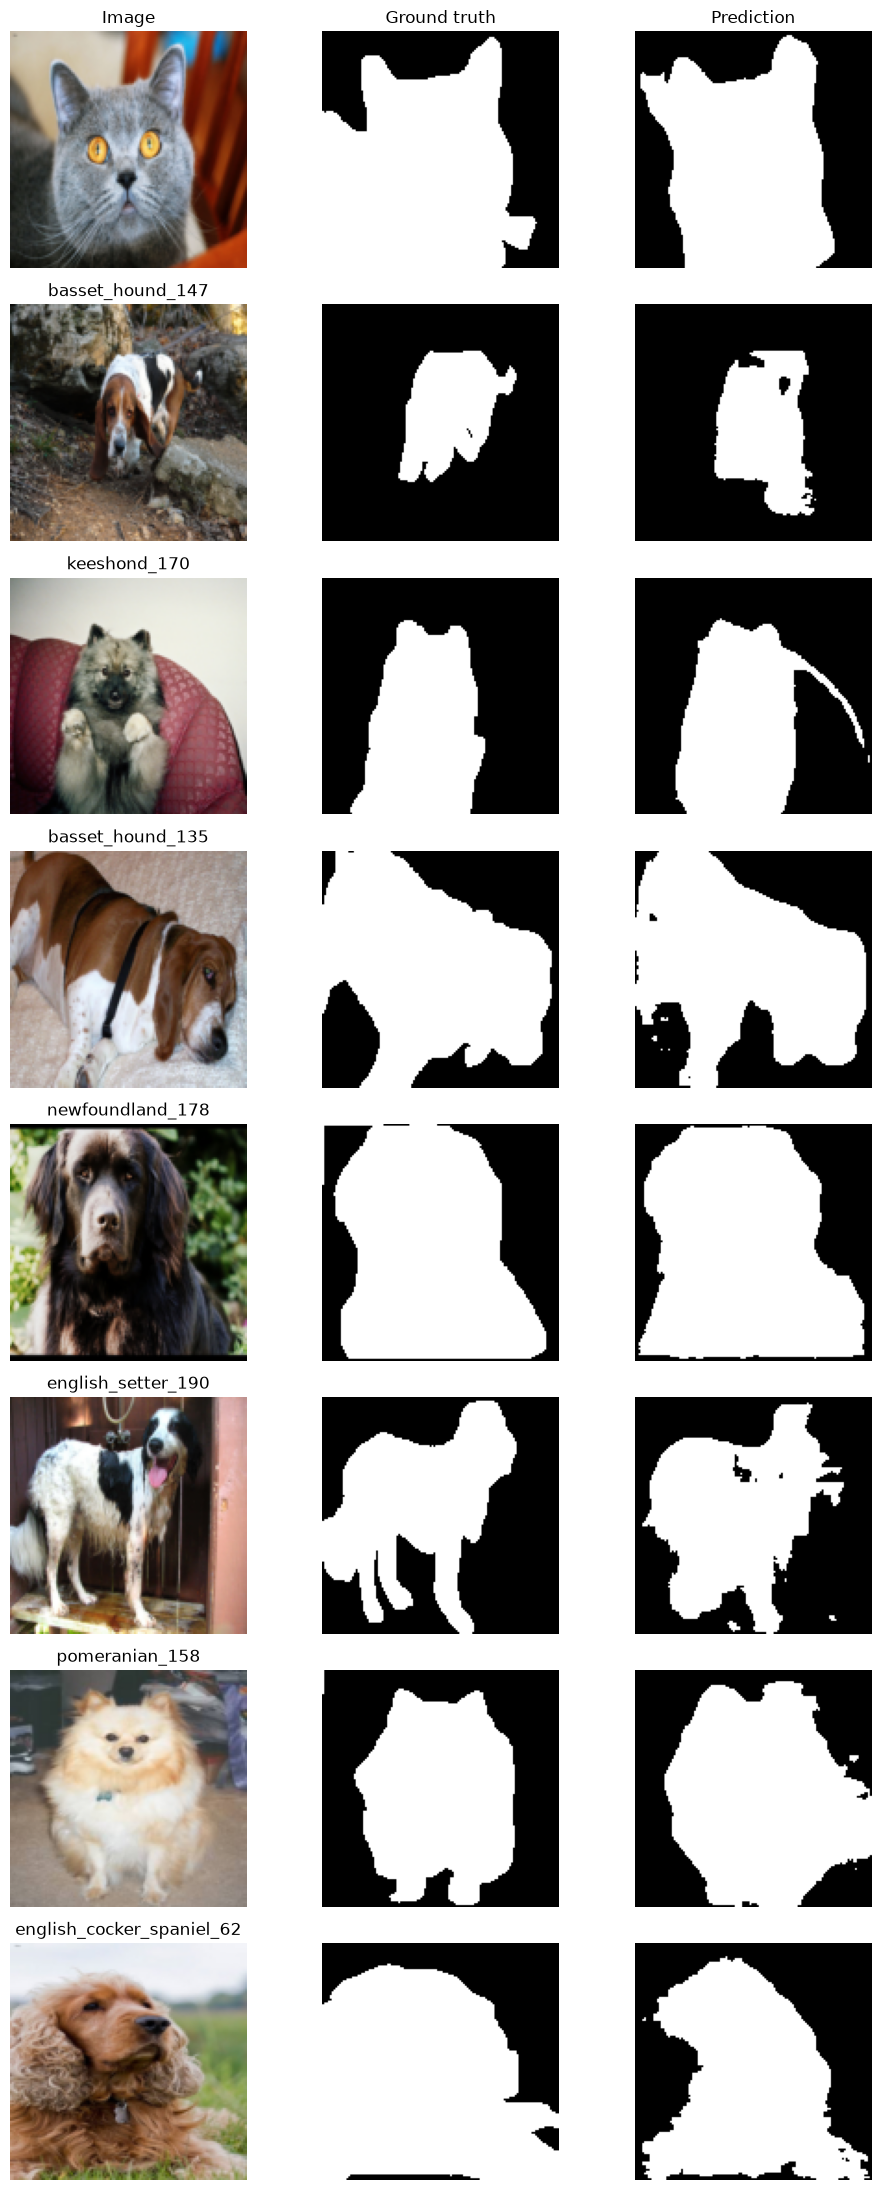

In [5]:
model.load_state_dict(torch.load('best_unet.pt',map_location=DEVICE,weights_only=True))
# Qualitative inspection after all model selection is complete.
model.eval();test_examples=Pets(test_ids)
fig,axes=plt.subplots(8,3,figsize=(10,22))
with torch.no_grad():
    for i in range(8):
        x,y=test_examples[i];pred=model(x[None].to(DEVICE)).sigmoid()[0,0].cpu()>=.5
        axes[i,0].imshow(x.permute(1,2,0));axes[i,1].imshow(y[0],cmap='gray');axes[i,2].imshow(pred,cmap='gray')
        for ax in axes[i]:ax.axis('off')
        axes[i,0].set_title(Path(records[test_ids[i]][0]).stem)
for ax,title in zip(axes[0],['Image','Ground truth','Prediction']):ax.set_title(title)
plt.tight_layout();plt.show()


## Results and failure discussion
Validation Dice selected epoch 9 (0.88036). The checkpoint was evaluated once on the held-out
test set: BCE 0.24316, micro Dice 0.87949, micro IoU 0.78491. These metrics aggregate pixels
across the split; they are not an unweighted mean of per-image Dice scores.
The eight test visualizations show both recognizable foreground masks and substantial errors.
For `basset_hound_147`, the prediction misses parts of the legs and separates the silhouette
incorrectly against the rocky ground: a small animal with background-like colours is difficult.
For `keeshond_170`, the mask includes a thin curved background structure on the right, a false
positive unrelated to the pet. `english_setter_190` also loses leg separation and includes nearby
background. Thus good aggregate overlap does not mean reliable boundaries on every image.
At 128×128, downsampling removes fine detail; BCE can favour smooth large regions. These are
post-selection test observations, not reasons used to choose a new model on the test set.
This is an executed local notebook; uploading it to Kaggle is deferred with the other Kaggle work.
